In [59]:
1+1

2

In [60]:
leafPath = r"..\data\ssvep_stim_frames\p998_b001_leaf_stimframes_20261014_165625426.csv"
paddlePath = r"..\data\ssvep_stim_frames\p998_b001_paddle_stimframes_20261014_170845911.csv"

import pandas as pd
import numpy as np

leafData = pd.read_csv(leafPath)
paddleData = pd.read_csv(paddlePath)

# NumPy array of the leaf data
leafArray = leafData.to_numpy()

# NumPy array of the paddle data
paddleArray = paddleData.to_numpy()

print("Leaf Data:")
print(leafData)
print("\nPaddle Data:")
print(paddleData)

Leaf Data:
       TimestampUnixMs  Stim17HzIntensity  Stim19HzIntensity
0        1791996986668           0.989074           0.956773
1        1791996986710           0.394698           0.740608
2        1791996986714           0.690575           0.961584
3        1791996986731           0.877960           0.996018
4        1791996986748           0.725589           0.223632
...                ...                ...                ...
21647    1791997462700           0.560743           0.742216
21648    1791997462716           0.001048           0.003156
21649    1791997462733           0.642238           0.658420
21650    1791997462750           0.927013           0.849682
21651    1791997462767           0.154869           0.030265

[21652 rows x 3 columns]

Paddle Data:
       TimestampUnixMs  Stim17HzIntensity  Stim19HzIntensity
0        1791997728584           0.999886           0.989152
1        1791997728601           0.371310           0.193231
2        1791997728618           0

In [61]:
timeLeaf = leafArray[:, 0]  # Assuming the first column is time
timePaddle = paddleArray[:, 0]  # Assuming the first column is time

stim17leaf = leafArray[:, 1]  # Assuming the second column is stim17 for leaf
stim17paddle = paddleArray[:, 1]  # Assuming the second column is stim17 for paddle

stim19leaf = leafArray[:, 2]  # Assuming the third column is stim19 for leaf
stim19paddle = paddleArray[:, 2]  # Assuming the third column is stim19 for paddle

print("\nTime Leaf:")
print(timeLeaf)
print("\nTime Paddle:")
print(timePaddle)

print("\nStim17 Leaf:")
print(stim17leaf)
print("\nStim17 Paddle:")
print(stim17paddle)

print("\nStim19 Leaf:")
print(stim19leaf)
print("\nStim19 Paddle:")
print(stim19paddle)


Time Leaf:
[1.79199699e+12 1.79199699e+12 1.79199699e+12 ... 1.79199746e+12
 1.79199746e+12 1.79199746e+12]

Time Paddle:
[1.79199773e+12 1.79199773e+12 1.79199773e+12 ... 1.79199806e+12
 1.79199806e+12 1.79199806e+12]

Stim17 Leaf:
[0.9890738  0.39469787 0.690575   ... 0.6422375  0.9270127  0.15486862]

Stim17 Paddle:
[0.9998858  0.37130982 0.05659452 ... 0.98884976 0.49250877 0.01242083]

Stim19 Leaf:
[0.95677274 0.740608   0.96158415 ... 0.65841955 0.84968215 0.03026487]

Stim19 Paddle:
[0.9891517  0.1932306  0.26933998 ... 0.85163224 0.6728322  0.00104883]


In [62]:
import matplotlib.pyplot as plt

## Join trials on a continuous timeline
Gaps greater than 1,000 ms start a new trial. Replace only these gaps with the median within-trial sample interval. Preserve intensities and original timestamps; gray lines mark boundaries. This closes pauses but does not guarantee matching stimulus phase at trial joins.


In [63]:
# A gap strictly greater than 1000 ms starts the next trial.
# Join the time axis; keep original timestamps and intensities unchanged.
def join_trials(data, gap_ms=1000):
    joined = data.copy()
    original_ms = pd.to_numeric(joined["TimestampUnixMs"]).to_numpy(dtype=np.float64)
    if len(original_ms) < 2:
        raise ValueError("At least two samples are required.")
    intervals = np.diff(original_ms)
    if not np.all(np.isfinite(original_ms)) or np.any(intervals <= 0):
        raise ValueError("Timestamps must be finite and strictly increasing in acquisition order.")
    boundaries = intervals > gap_ms
    within_trial = intervals[~boundaries]
    if not len(within_trial):
        raise ValueError("No within-trial intervals are available to estimate sample spacing.")
    sample_ms = float(np.median(within_trial))
    joined_ms = np.r_[0.0, np.cumsum(np.where(boundaries, sample_ms, intervals))]
    joined["Trial"] = np.r_[1, 1 + np.cumsum(boundaries)]
    joined["JoinedTimeMs"] = joined_ms
    joined["JoinedTimeSeconds"] = joined_ms / 1000.0
    assert np.allclose(np.diff(joined_ms)[~boundaries], intervals[~boundaries])
    assert np.allclose(np.diff(joined_ms)[boundaries], sample_ms)
    print(f"{len(joined):,} samples, {int(joined['Trial'].max())} trials; boundary spacing {sample_ms:g} ms")
    return joined

leafJoined = join_trials(leafData)
paddleJoined = join_trials(paddleData)

# Continuous plotting arrays; the original timeLeaf/timePaddle remain available.
timeLeafJoined = leafJoined["JoinedTimeSeconds"].to_numpy()
timePaddleJoined = paddleJoined["JoinedTimeSeconds"].to_numpy()

print("\nJoined Leaf Data:")
print(leafJoined)
print("\nJoined Paddle Data:")
print(paddleJoined)


21,652 samples, 24 trials; boundary spacing 17 ms
17,306 samples, 24 trials; boundary spacing 17 ms

Joined Leaf Data:
       TimestampUnixMs  Stim17HzIntensity  Stim19HzIntensity  Trial  \
0        1791996986668           0.989074           0.956773      1   
1        1791996986710           0.394698           0.740608      1   
2        1791996986714           0.690575           0.961584      1   
3        1791996986731           0.877960           0.996018      1   
4        1791996986748           0.725589           0.223632      1   
...                ...                ...                ...    ...   
21647    1791997462700           0.560743           0.742216     24   
21648    1791997462716           0.001048           0.003156     24   
21649    1791997462733           0.642238           0.658420     24   
21650    1791997462750           0.927013           0.849682     24   
21651    1791997462767           0.154869           0.030265     24   

       JoinedTimeMs  JoinedT

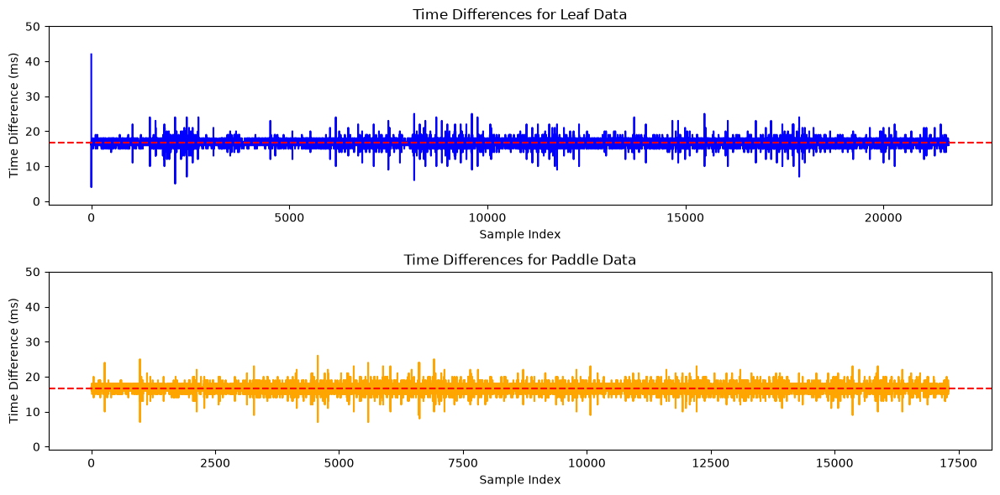

In [64]:
leafTime = leafJoined["JoinedTimeMs"].to_numpy()
paddleTime = paddleJoined["JoinedTimeMs"].to_numpy()
leafStim17 = leafJoined["Stim17HzIntensity"].to_numpy()
paddleStim17 = paddleJoined["Stim17HzIntensity"].to_numpy()
leafStim19 = leafJoined["Stim19HzIntensity"].to_numpy()
paddleStim19 = paddleJoined["Stim19HzIntensity"].to_numpy()

deltaTimeLeaf = np.diff(leafTime)
deltaTimePaddle = np.diff(paddleTime)

# Plotting the time differences for leaf and paddle data
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(deltaTimeLeaf, label='Leaf Time Differences', color='blue')
plt.axhline(y=(1000/60), color='red', linestyle='--', label='1 Second Threshold')
plt.title('Time Differences for Leaf Data')
plt.xlabel('Sample Index')
plt.ylabel('Time Difference (ms)')
plt.ylim(-1, 50)
plt.subplot(2, 1, 2)
plt.plot(deltaTimePaddle, label='Paddle Time Differences', color='orange')
plt.axhline(y=(1000/60), color='red', linestyle='--', label='1 Second Threshold')
plt.title('Time Differences for Paddle Data')
plt.xlabel('Sample Index')
plt.ylabel('Time Difference (ms)')
plt.ylim(-1, 50)
plt.tight_layout()

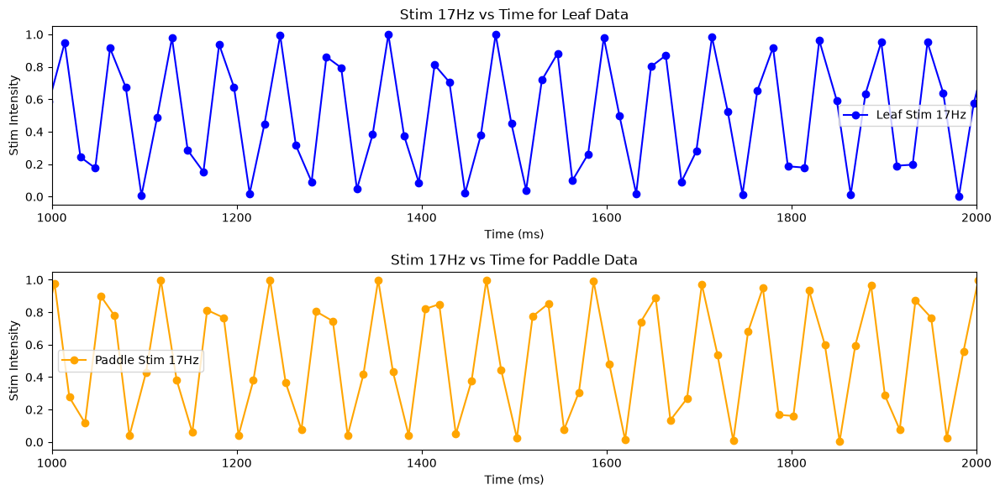

In [65]:
# Plot stim 17 vs time(ms) for leaf and paddle data
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(leafTime, leafStim17, label='Leaf Stim 17Hz', color='blue', marker='o')
plt.title('Stim 17Hz vs Time for Leaf Data')
plt.xlabel('Time (ms)')
plt.ylabel('Stim Intensity')
plt.xlim(1000, 2000)
plt.legend()
plt.subplot(2, 1, 2)
plt.plot(paddleTime, paddleStim17, label='Paddle Stim 17Hz', color='orange', marker='o')
plt.title('Stim 17Hz vs Time for Paddle Data')
plt.xlabel('Time (ms)')
plt.ylabel('Stim Intensity')
plt.xlim(1000, 2000)
plt.legend()
plt.tight_layout()

## Inspect one original trial in 1-second windows
Set `LEAF_TRIAL` and `PADDLE_TRIAL` below (numbering starts at 1). Trials are split only where the original timestamp gap is greater than 1,000 ms. Each game has a separate figure showing both stimulus channels in consecutive non-overlapping 1-second windows, from its first recorded stimulus sample through its last. Include the final partial window.


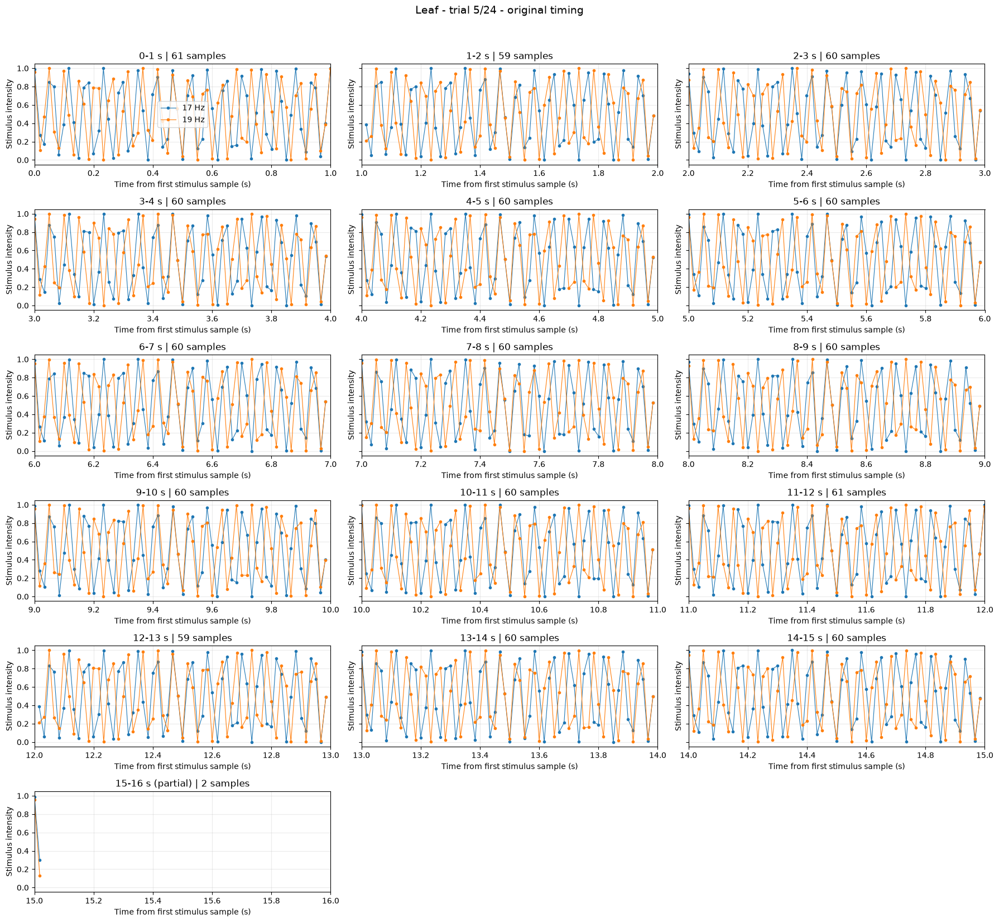

Leaf: trial 5/24, 902 samples, 15.018 s, 16 windows (final partial included).


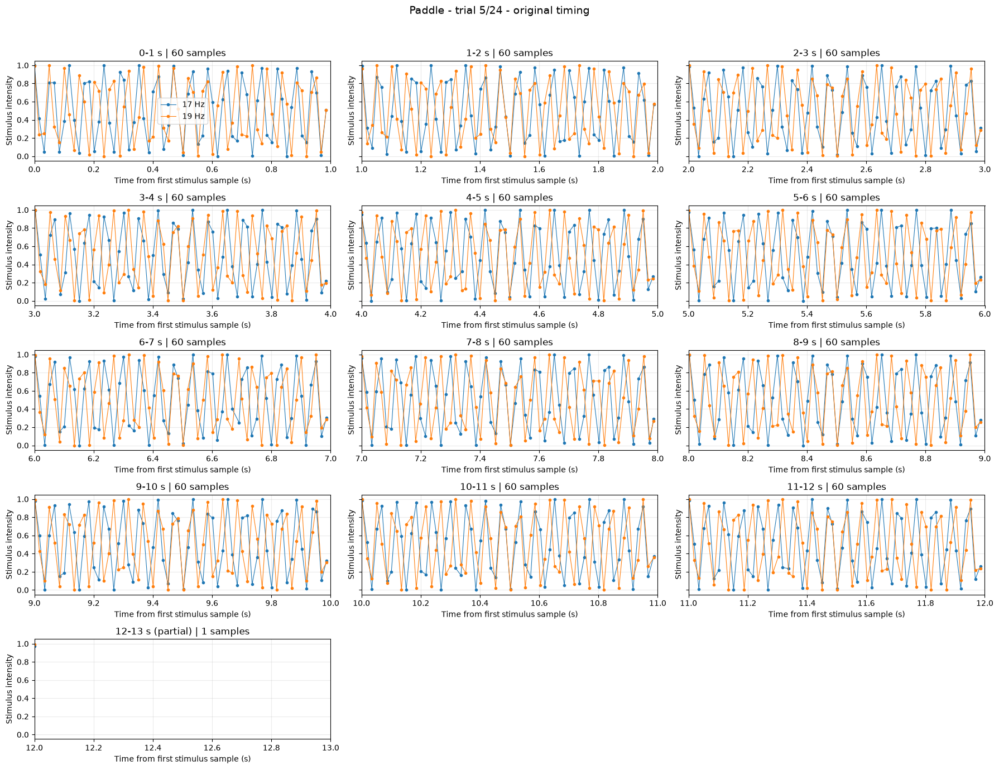

Paddle: trial 5/24, 721 samples, 12.001 s, 13 windows (final partial included).


In [66]:
# Change these 1-based trial numbers manually, then rerun this cell.
LEAF_TRIAL = 5
PADDLE_TRIAL = 5


def plot_trial_seconds(data, trial_number, game):
    """Plot every sample of one original trial in non-overlapping 1 s windows."""
    timestamp_ms = pd.to_numeric(data["TimestampUnixMs"]).to_numpy(dtype=np.float64)
    if not len(timestamp_ms):
        raise ValueError(f"{game}: no samples available.")
    if not np.all(np.isfinite(timestamp_ms)) or np.any(np.diff(timestamp_ms) <= 0):
        raise ValueError(f"{game}: timestamps must be finite and strictly increasing.")
    trial_ids = np.r_[1, 1 + np.cumsum(np.diff(timestamp_ms) > 1000)]
    total_trials = int(trial_ids[-1])
    if not isinstance(trial_number, (int, np.integer)) or not 1 <= trial_number <= total_trials:
        raise ValueError(f"{game}: choose a trial number from 1 to {total_trials}.")

    trial = data.loc[trial_ids == trial_number].copy()
    original_trial_ms = timestamp_ms[trial_ids == trial_number]
    elapsed_ms = original_trial_ms - original_trial_ms[0]
    # Half-open windows [0, 1000), [1000, 2000), ... assign each sample once.
    window_ids = (elapsed_ms // 1000).astype(int)
    window_count = int(window_ids[-1]) + 1
    cols = min(3, window_count)
    rows = (window_count + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 2.8 * rows),
                             squeeze=False, sharey=True)
    for window, ax in enumerate(axes.flat):
        if window >= window_count:
            ax.set_visible(False)
            continue
        mask = window_ids == window
        start_s = float(window)
        end_s = start_s + 1
        for column, label, color in [
            ("Stim17HzIntensity", "17 Hz", "tab:blue"),
            ("Stim19HzIntensity", "19 Hz", "tab:orange"),
        ]:
            ax.plot(elapsed_ms[mask] / 1000, trial[column].to_numpy()[mask],
                    marker="o", markersize=3, linewidth=0.8, label=label, color=color)
        partial = window == window_count - 1 and elapsed_ms[-1] < (window + 1) * 1000
        suffix = " (partial)" if partial else ""
        ax.set_title(f"{start_s:g}-{end_s:g} s{suffix} | {int(mask.sum())} samples")
        ax.set_xlim(start_s, end_s)
        ax.set_xlabel("Time from first stimulus sample (s)")
        ax.set_ylabel("Stimulus intensity")
        ax.grid(alpha=0.25)
        if window == 0:
            ax.legend(loc="best")
    fig.suptitle(f"{game} - trial {trial_number}/{total_trials} - original timing", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()
    print(f"{game}: trial {trial_number}/{total_trials}, {len(trial):,} samples, "
          f"{elapsed_ms[-1] / 1000:.3f} s, {window_count} windows (final partial included).")
    return trial


# Uses the raw DataFrames, independent of the artificial joined timeline.
leafSelectedTrial = plot_trial_seconds(leafData, LEAF_TRIAL, "Leaf")
paddleSelectedTrial = plot_trial_seconds(paddleData, PADDLE_TRIAL, "Paddle")


## FFT power and phase for all trial epochs
Edit `EPOCH_SECONDS` below (positive integer; default 1). Split original timestamps at gaps strictly greater than 1,000 ms. Within each trial, use consecutive half-open windows starting at its first sample and discard the final occupied window, whether full or partial. Trials shorter than one window contribute no FFT epochs.
For each retained epoch and each stimulus channel separately, linearly resample inside that epoch, subtract its mean, apply a Hann window, and compute a one-sided FFT power spectral density and wrapped phase in degrees. Phase is relative to the first resampled sample of each epoch; it is not aligned across trials. Interpolation handles timestamp jitter but can alter high-frequency content.
Each trial gets separate power and phase figures, with one panel per retained epoch and both stimulus channels. Dotted lines mark 17 and 19 Hz. Results remain available as `leafEpochSpectra`, `paddleEpochSpectra`, and `epochFFTAudit`.


  game  trial  samples  dropped_epoch  dropped_start_s  dropped_samples  retained_epochs
  Leaf      1      903             16               15                3               15
  Leaf      2      902             16               15                2               15
  Leaf      3      902             16               15                1               15
  Leaf      4      902             16               15                2               15
  Leaf      5      902             16               15                2               15
  Leaf      6      902             16               15                2               15
  Leaf      7      902             16               15                2               15
  Leaf      8      902             16               15                2               15
  Leaf      9      902             16               15                2               15
  Leaf     10      902             16               15                2               15
  Leaf     11      90

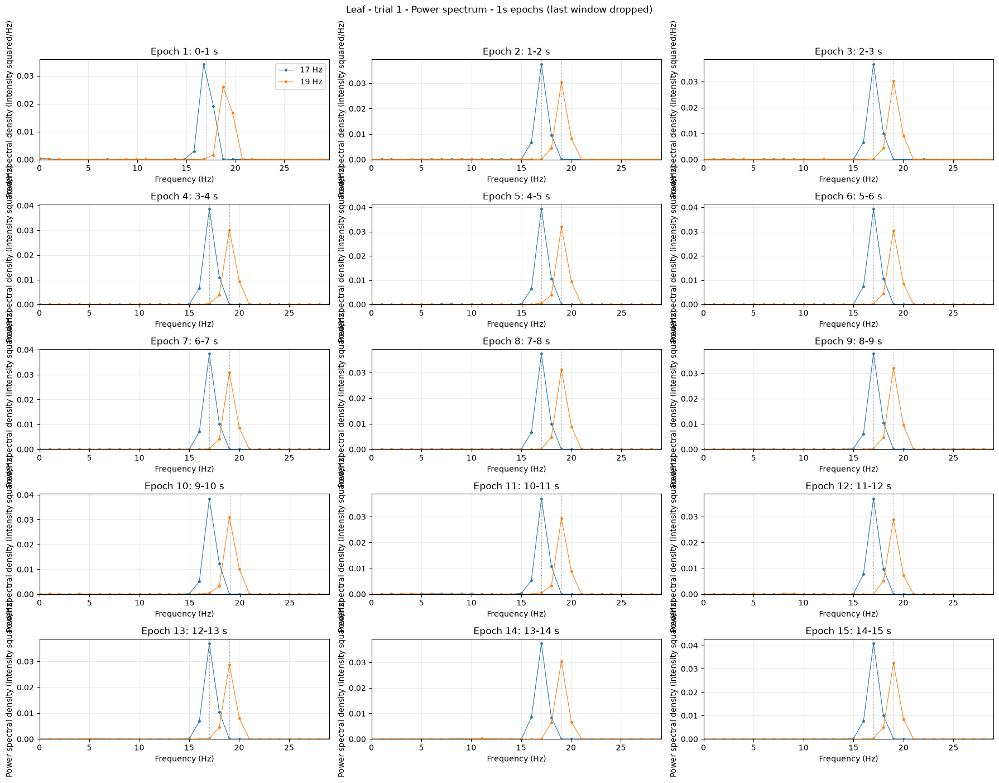

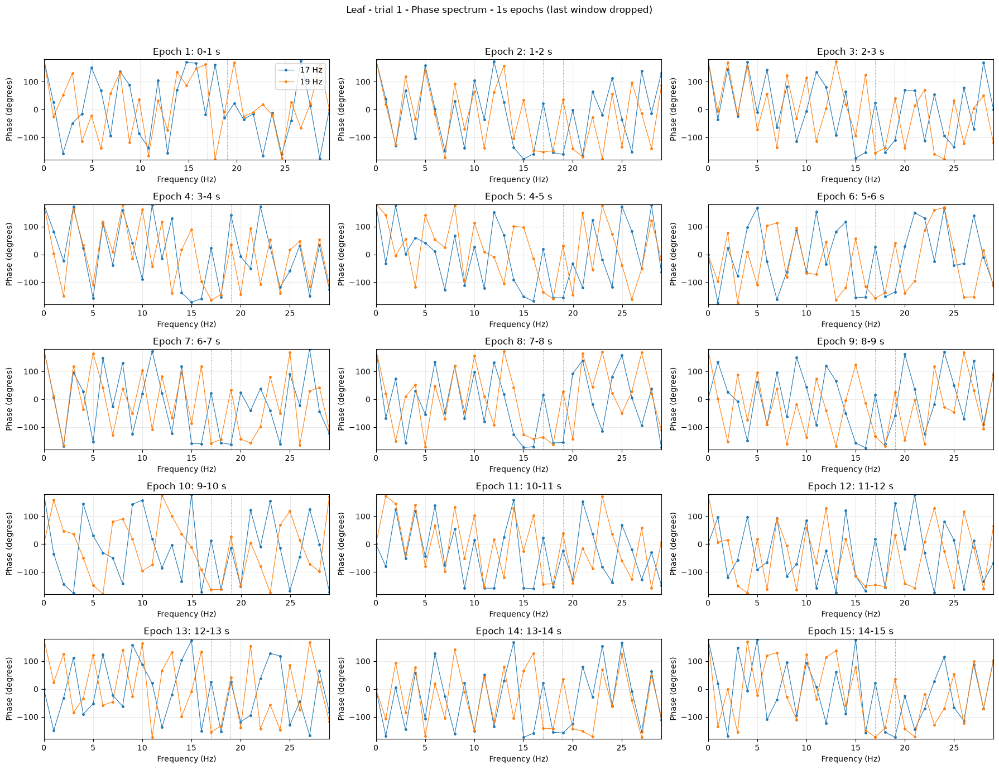

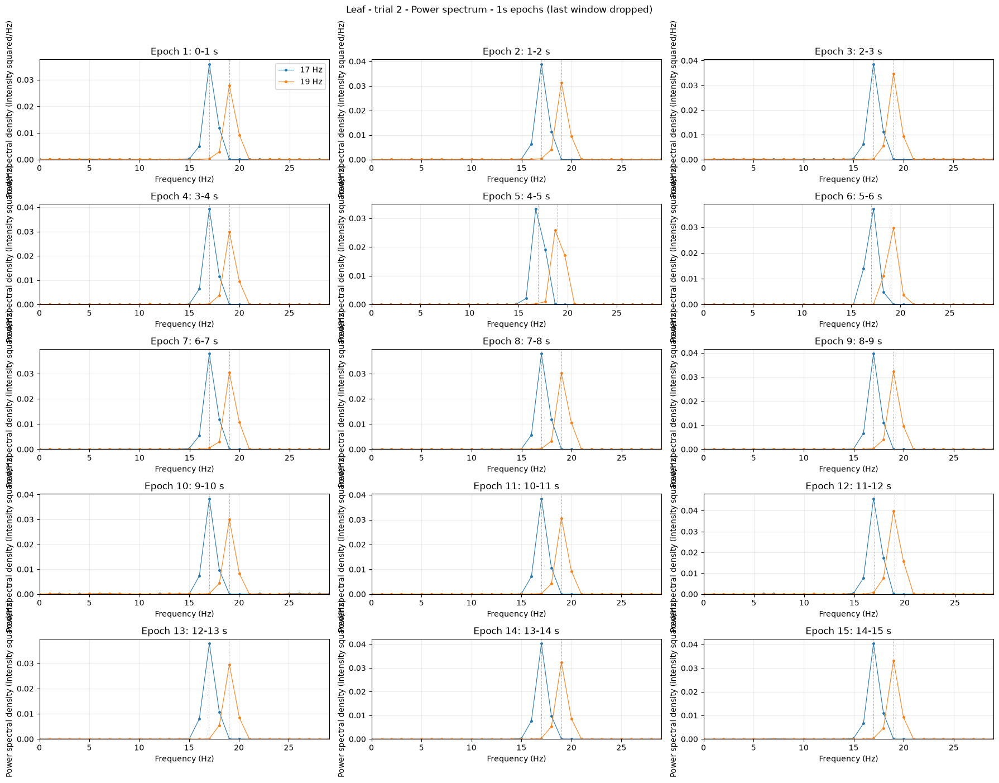

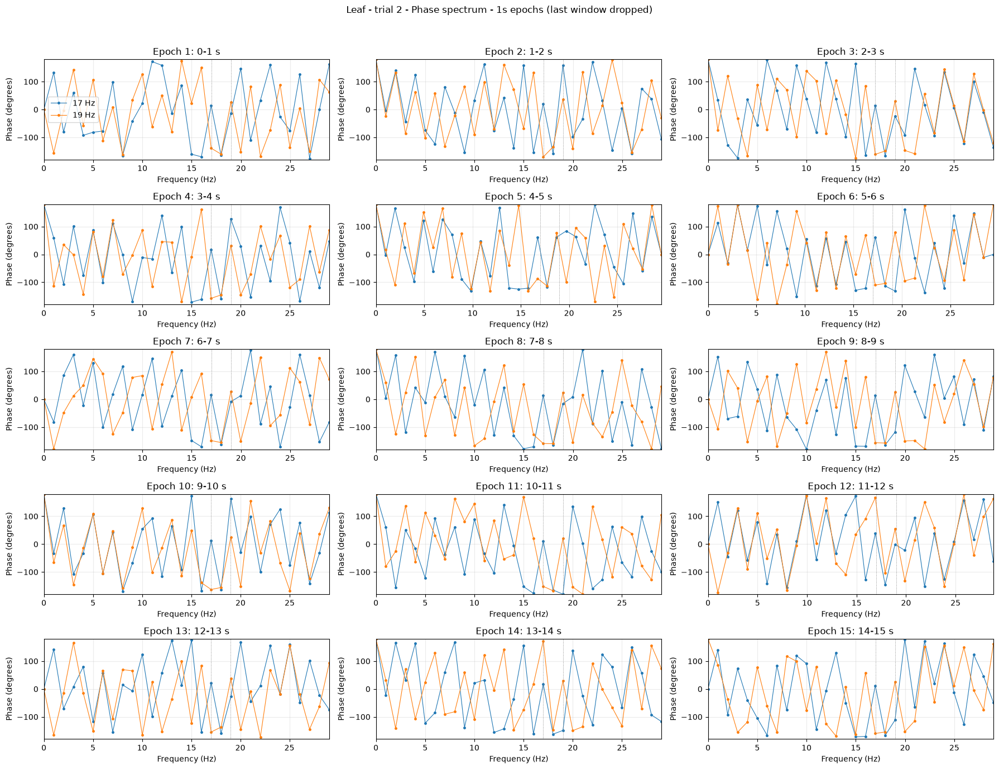

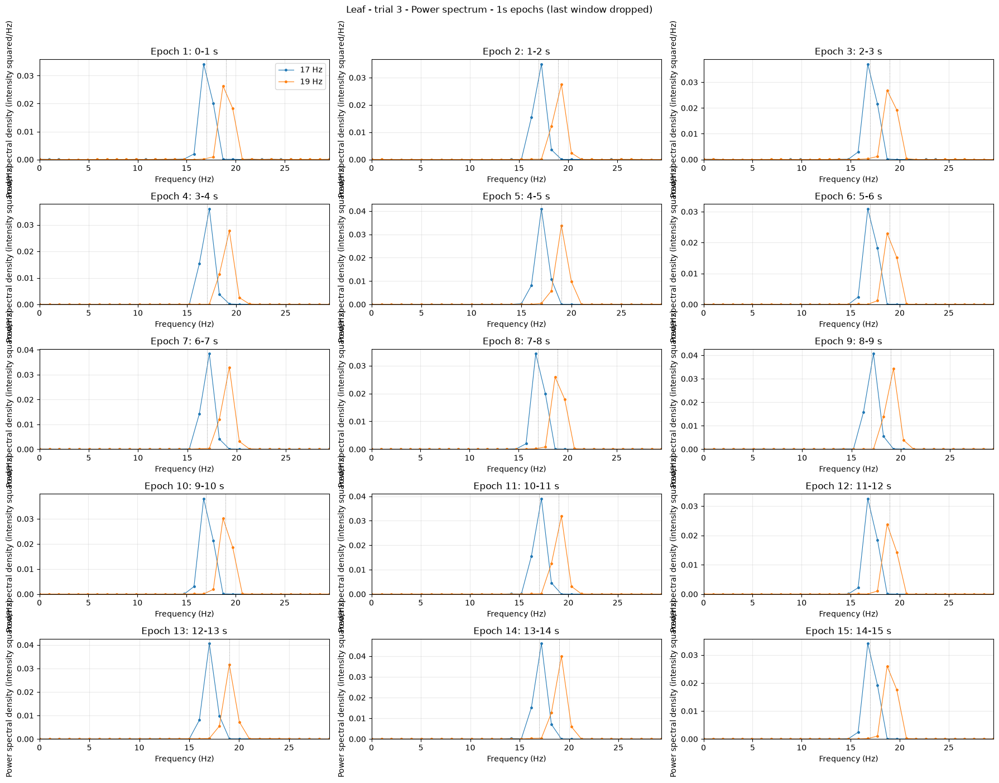

...

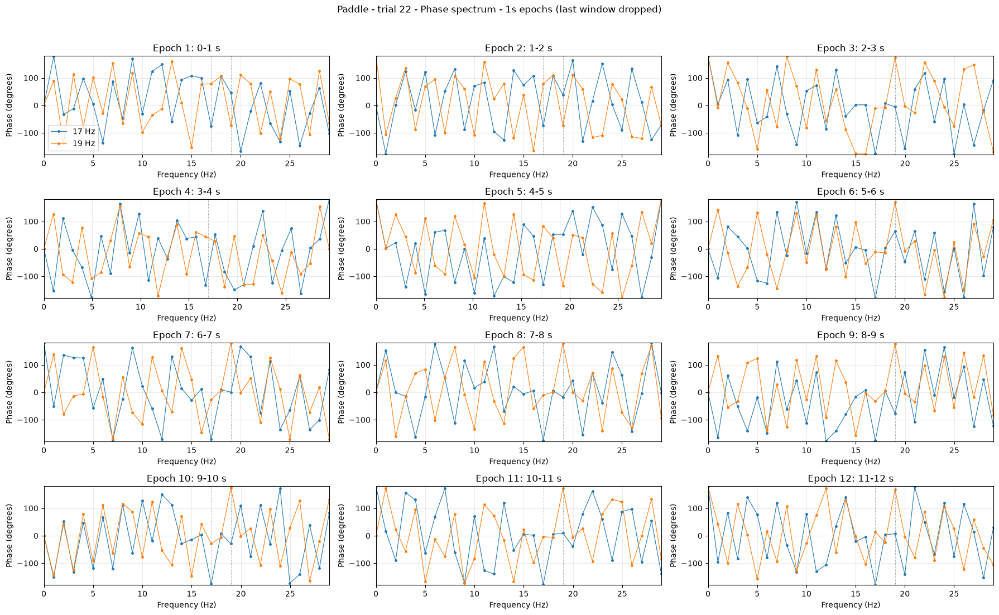

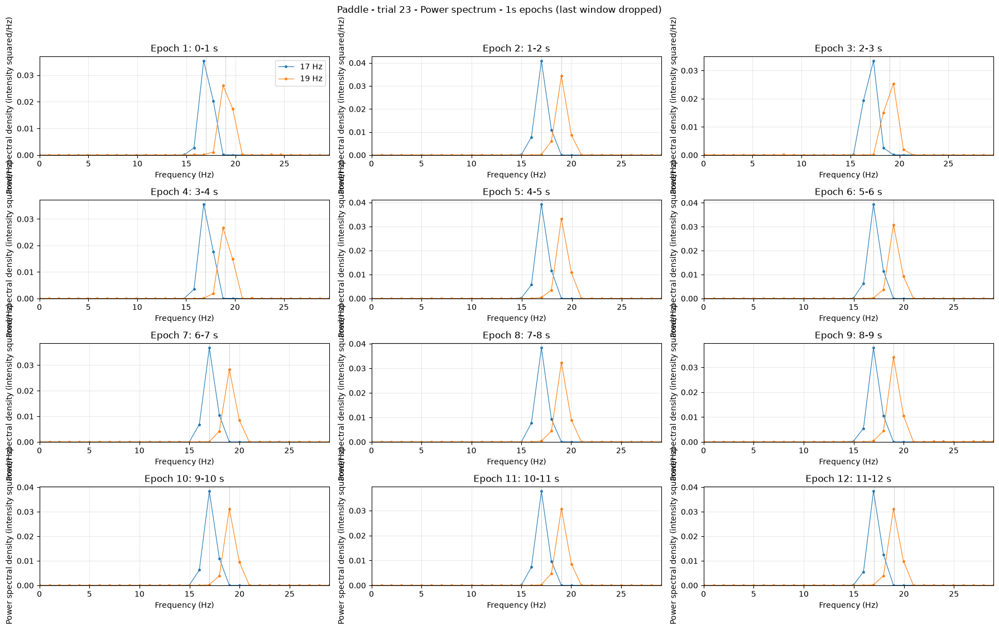

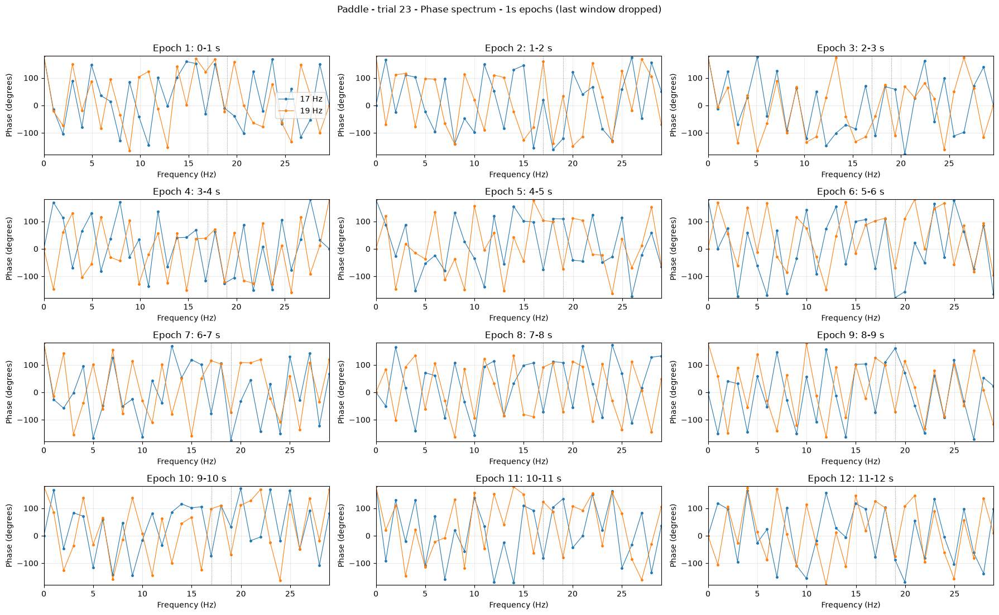

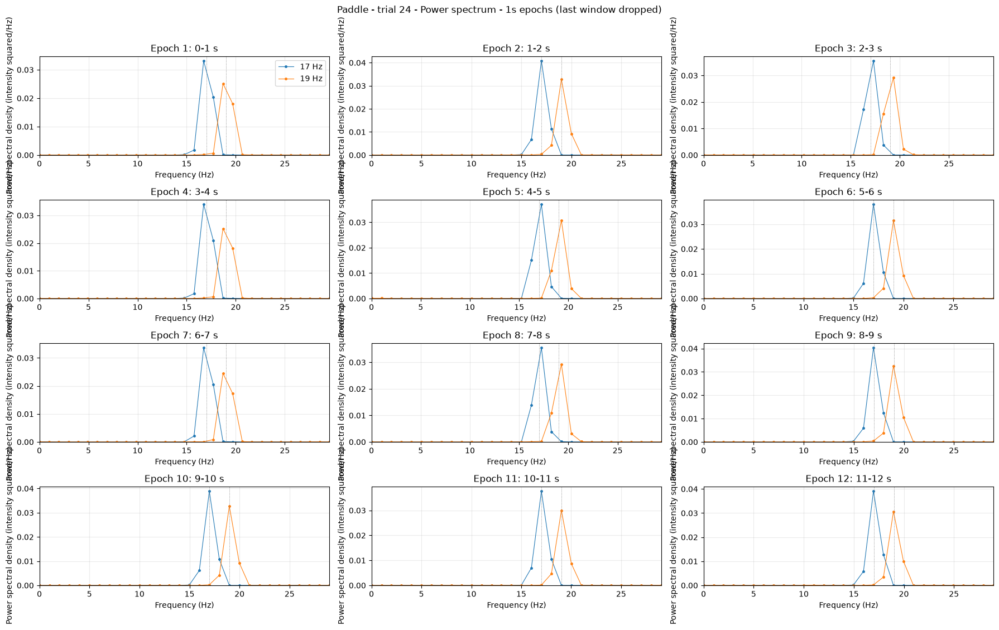

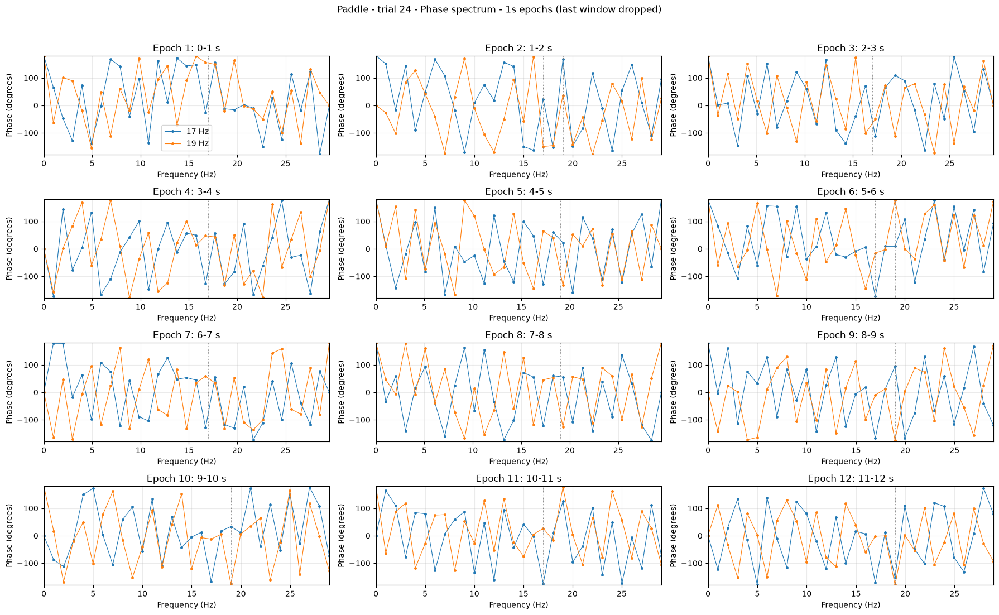

In [67]:
# Positive integer seconds. Re-run this cell after changing the duration.
EPOCH_SECONDS = 1


def trial_epoch_fft(data, game, epoch_seconds=1):
    if isinstance(epoch_seconds, (bool, np.bool_)) or not isinstance(epoch_seconds, (int, np.integer)) or epoch_seconds < 1:
        raise ValueError("EPOCH_SECONDS must be a positive integer.")
    timestamps = pd.to_numeric(data["TimestampUnixMs"]).to_numpy(dtype=float)
    if len(timestamps) == 0 or not np.all(np.isfinite(timestamps)) or np.any(np.diff(timestamps) <= 0):
        raise ValueError(f"{game}: timestamps must be finite and strictly increasing.")
    trial_ids = np.r_[1, 1 + np.cumsum(np.diff(timestamps) > 1000)]
    spectra, audit = [], []
    for trial_id in range(1, int(trial_ids[-1]) + 1):
        trial = data.loc[trial_ids == trial_id]
        trial_ms = timestamps[trial_ids == trial_id]
        elapsed = (trial_ms - trial_ms[0]) / 1000
        epoch_ids = (elapsed // epoch_seconds).astype(int)
        last_epoch = int(epoch_ids[-1])
        # Always drop the final occupied window, even when it is a full window.
        audit.append(dict(game=game, trial=trial_id, samples=len(trial),
                          dropped_epoch=last_epoch + 1,
                          dropped_start_s=last_epoch * epoch_seconds,
                          dropped_samples=int(np.sum(epoch_ids == last_epoch)),
                          retained_epochs=last_epoch))
        for epoch_id in range(last_epoch):
            mask = epoch_ids == epoch_id
            t = elapsed[mask]
            if len(t) < 4:
                raise ValueError(f"{game}, trial {trial_id}, epoch {epoch_id + 1}: fewer than 4 samples.")
            # Uniform sampling is required by the FFT. Interpolate only inside
            # this epoch's recorded support: no cross-epoch/trial interpolation.
            nominal_dt = float(np.median(np.diff(t)))
            sample_count = max(4, int(round((t[-1] - t[0]) / nominal_dt)) + 1)
            uniform_t = np.linspace(t[0], t[-1], sample_count)
            fs = (sample_count - 1) / (t[-1] - t[0])
            taper = np.hanning(sample_count)
            frequency = np.fft.rfftfreq(sample_count, d=1 / fs)
            for column, signal in [("Stim17HzIntensity", "17 Hz"),
                                   ("Stim19HzIntensity", "19 Hz")]:
                values = pd.to_numeric(trial[column]).to_numpy(dtype=float)[mask]
                if not np.all(np.isfinite(values)):
                    raise ValueError(f"{game}, trial {trial_id}: non-finite {column} values.")
                uniform_values = np.interp(uniform_t, t, values)
                centered = uniform_values - uniform_values.mean()
                fft = np.fft.rfft(centered * taper)
                # One-sided power spectral density, intensity^2 / Hz.
                power = np.abs(fft) ** 2 / (fs * np.sum(taper ** 2))
                if sample_count % 2 == 0:
                    power[1:-1] *= 2
                else:
                    power[1:] *= 2
                phase = np.angle(fft, deg=True)
                # Phase has no useful meaning at effectively zero-power bins.
                phase[power <= power.max() * 1e-12] = np.nan
                spectra.append(dict(game=game, trial=trial_id, epoch=epoch_id + 1,
                                    start_s=epoch_id * epoch_seconds,
                                    end_s=(epoch_id + 1) * epoch_seconds,
                                    signal=signal, original_samples=len(t),
                                    resampled_samples=sample_count, fs_hz=fs,
                                    phase_origin_s=float(t[0]), frequency_hz=frequency,
                                    power_psd=power, phase_degrees=phase))
    return spectra, pd.DataFrame(audit)


def plot_epoch_spectra(spectra, game, epoch_seconds):
    for trial_id in sorted({s["trial"] for s in spectra}):
        trial_spectra = [s for s in spectra if s["trial"] == trial_id]
        epochs = sorted({s["epoch"] for s in trial_spectra})
        cols = min(3, len(epochs))
        rows = (len(epochs) + cols - 1) // cols
        for field, title, ylabel in [
            ("power_psd", "Power spectrum", "Power spectral density (intensity squared/Hz)"),
            ("phase_degrees", "Phase spectrum", "Phase (degrees)"),
        ]:
            fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 2.8 * rows), squeeze=False)
            for panel, ax in enumerate(axes.flat):
                if panel >= len(epochs):
                    ax.set_visible(False)
                    continue
                epoch = epochs[panel]
                records = [s for s in trial_spectra if s["epoch"] == epoch]
                for record in records:
                    ax.plot(record["frequency_hz"], record[field], marker="o",
                            markersize=2.5, linewidth=0.8, label=record["signal"])
                for target in (17, 19):
                    ax.axvline(target, color="gray", linestyle=":", linewidth=0.7)
                ax.set_title(f"Epoch {epoch}: {records[0]['start_s']:g}-{records[0]['end_s']:g} s")
                ax.set_xlabel("Frequency (Hz)")
                ax.set_ylabel(ylabel)
                ax.set_xlim(0, max(r["frequency_hz"][-1] for r in records))
                if field == "phase_degrees":
                    ax.set_ylim(-180, 180)
                else:
                    ax.set_ylim(bottom=0)
                ax.grid(alpha=0.25)
                if panel == 0:
                    ax.legend()
            fig.suptitle(f"{game} - trial {trial_id} - {title} - {epoch_seconds}s epochs (last window dropped)")
            fig.tight_layout(rect=(0, 0, 1, 0.96))
            plt.show()
            plt.close(fig)


# Process ALL trials directly from original data, independent of trial selectors.
leafEpochSpectra, leafEpochAudit = trial_epoch_fft(leafData, "Leaf", EPOCH_SECONDS)
paddleEpochSpectra, paddleEpochAudit = trial_epoch_fft(paddleData, "Paddle", EPOCH_SECONDS)
epochFFTAudit = pd.concat([leafEpochAudit, paddleEpochAudit], ignore_index=True)
print(epochFFTAudit.to_string(index=False))
plot_epoch_spectra(leafEpochSpectra, "Leaf", EPOCH_SECONDS)
plot_epoch_spectra(paddleEpochSpectra, "Paddle", EPOCH_SECONDS)


## Power and phase grouped separately, with one subplot per trial
Each game gets two figures: a grid of all trial power time series, then a grid of all trial phase time series. Each subplot contains both stimulus channels and uses time from its own trial's first sample, with points at epoch centers. Final windows remain excluded and trials stay separate.
Use the nearest FFT bin to 17 Hz for the 17 Hz stimulus and to 19 Hz for the 19 Hz stimulus; actual frequencies are stored in `fft_bin_hz`. Phase is wrapped in degrees and relative to each epoch's first sample. Re-run the FFT cell first after changing `EPOCH_SECONDS`.


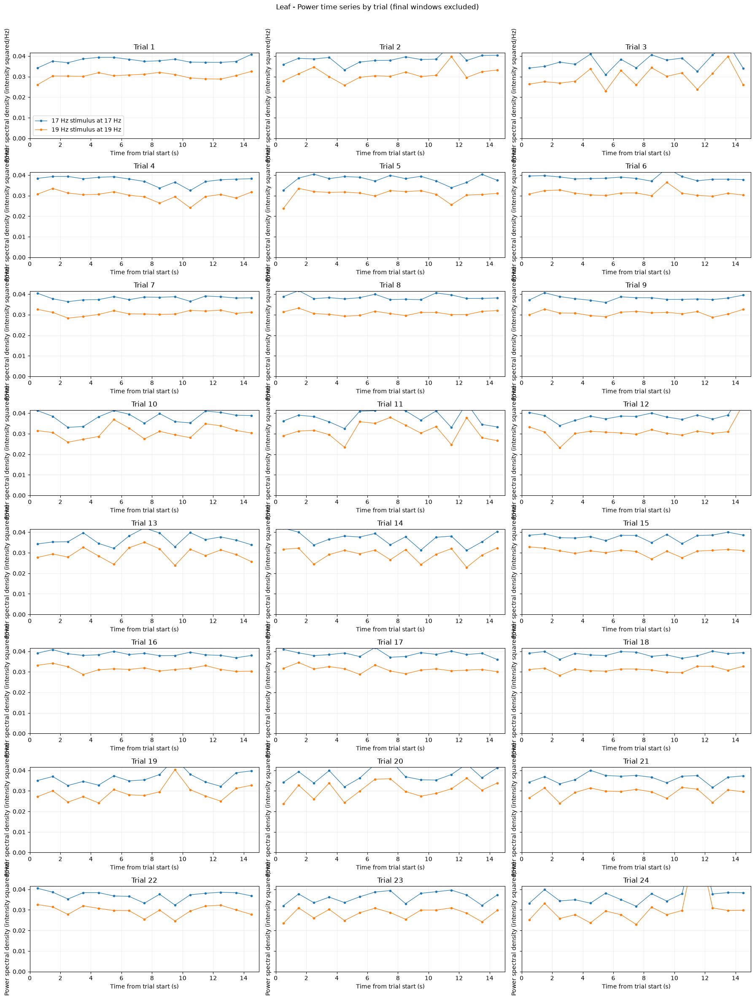

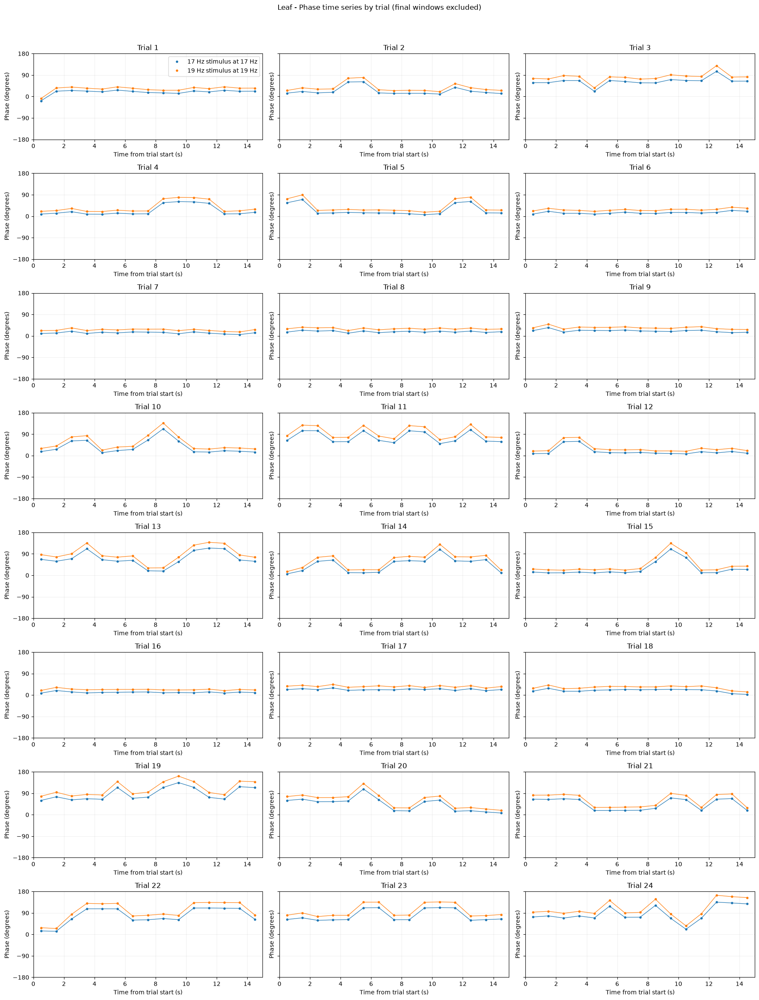

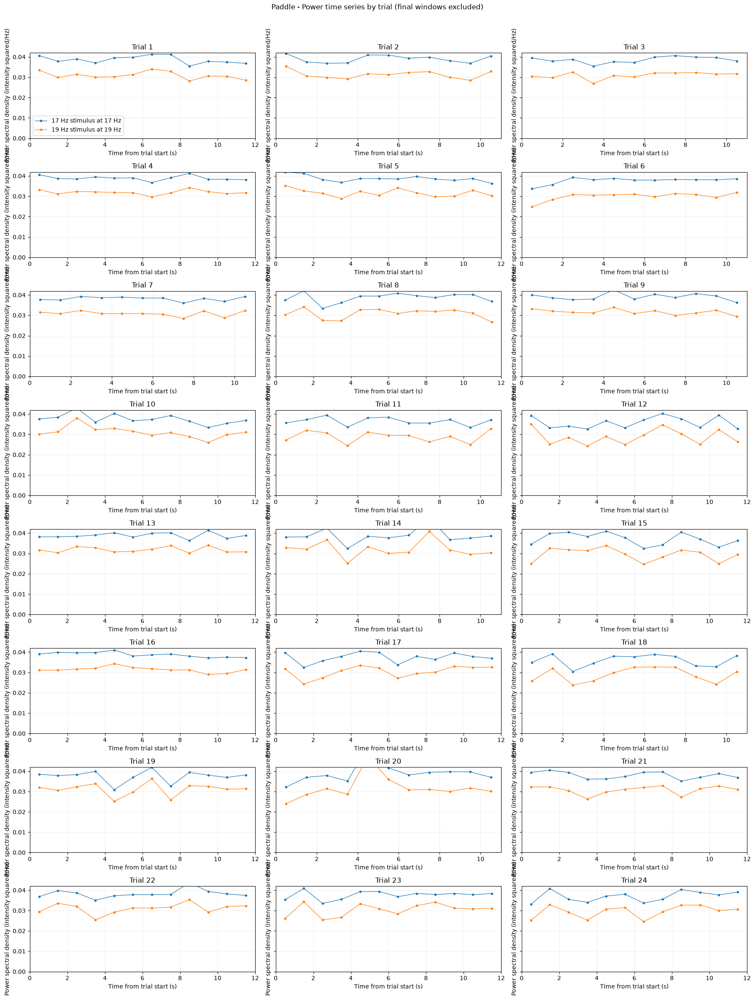

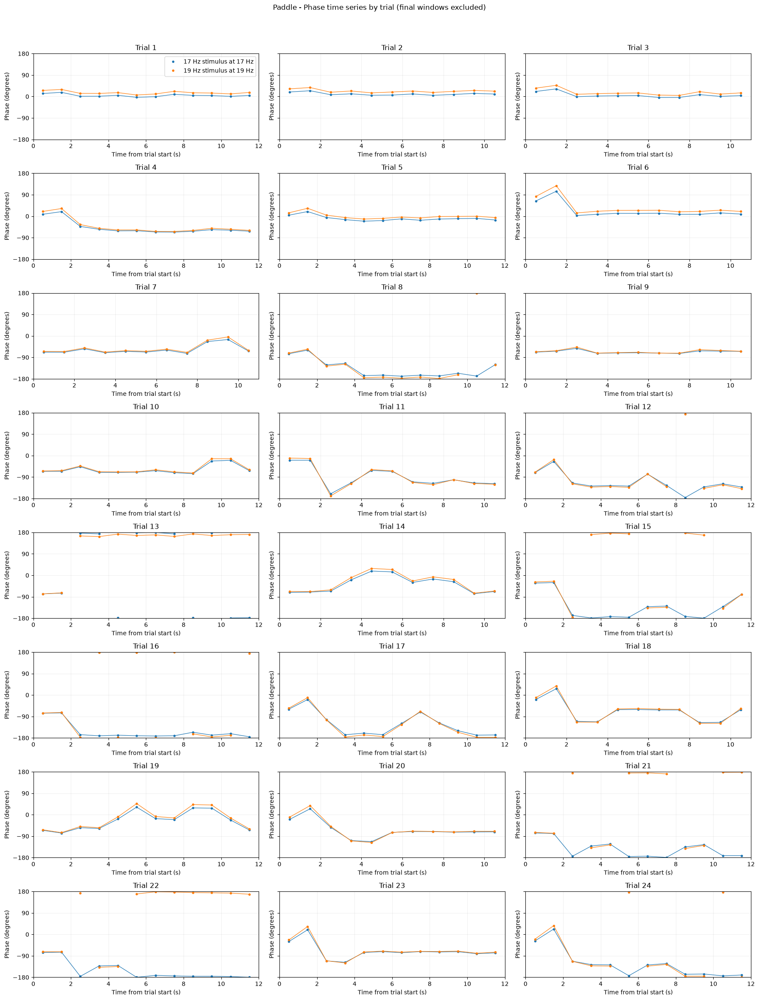

In [68]:
def extract_epoch_target_series(spectra):
    """One power/phase point per retained epoch and stimulus channel."""
    columns = ["game", "trial", "epoch", "signal", "target_hz", "fft_bin_hz",
               "power_psd", "phase_degrees", "trial_epoch_center_s", "time_s",
               "trial_start_s", "epoch_seconds"]
    if not spectra:
        return pd.DataFrame(columns=columns)
    rows = []
    for trial_id in sorted({s["trial"] for s in spectra}):
        records = sorted([s for s in spectra if s["trial"] == trial_id],
                         key=lambda s: (s["epoch"], s["signal"]))
        for record in records:
            target = 17.0 if record["signal"] == "17 Hz" else 19.0
            frequency = record["frequency_hz"]
            if target > frequency[-1]:
                raise ValueError(f"{record['game']}, trial {trial_id}, epoch {record['epoch']}: "
                                 f"{target:g} Hz exceeds the available FFT frequency range.")
            index = int(np.argmin(np.abs(frequency - target)))
            rows.append(dict(game=record["game"], trial=trial_id, epoch=record["epoch"],
                             signal=record["signal"], target_hz=target,
                             fft_bin_hz=float(frequency[index]),
                             power_psd=float(record["power_psd"][index]),
                             phase_degrees=float(record["phase_degrees"][index]),
                             trial_epoch_center_s=(record["start_s"] + record["end_s"]) / 2,
                             time_s=(record["start_s"] + record["end_s"]) / 2, trial_start_s=0.0,
                             epoch_seconds=record["end_s"] - record["start_s"]))
    return pd.DataFrame(rows, columns=columns)


def plot_epoch_target_series(series, game):
    if series.empty:
        print(f"{game}: no retained epochs to plot.")
        return
    trials = sorted(series["trial"].unique())
    cols = min(3, len(trials))
    rows = (len(trials) + cols - 1) // cols
    for field, title, ylabel in [
        ("power_psd", "Power", "Power spectral density (intensity squared/Hz)"),
        ("phase_degrees", "Phase", "Phase (degrees)"),
    ]:
        fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 3 * rows),
                                 squeeze=False, sharey=True)
        for panel, ax in enumerate(axes.flat):
            if panel >= len(trials):
                ax.set_visible(False)
                continue
            trial_id = trials[panel]
            trial_series = series.loc[series["trial"] == trial_id]
            for signal, color in [("17 Hz", "tab:blue"), ("19 Hz", "tab:orange")]:
                channel = trial_series.loc[trial_series["signal"] == signal].sort_values("time_s")
                t = channel["time_s"].to_numpy()
                values = channel[field].to_numpy()
                label = f"{signal} stimulus at {signal}"
                if field == "power_psd":
                    ax.plot(t, values, color=color, marker="o", markersize=3,
                            linewidth=0.9, label=label)
                else:
                    ax.plot(t, values, color=color, marker="o", markersize=3,
                            linestyle="None", label=label)
                    # Avoid connecting across the +/-180 degree phase wrap.
                    for j in range(1, len(t)):
                        if np.isfinite(values[j-1:j+1]).all() and abs(values[j] - values[j-1]) <= 180:
                            ax.plot(t[j-1:j+1], values[j-1:j+1], color=color, linewidth=0.9)
            ax.set_title(f"Trial {trial_id}")
            ax.set_xlabel("Time from trial start (s)")
            ax.set_ylabel(ylabel)
            end_s = float((trial_series["time_s"] + trial_series["epoch_seconds"] / 2).max())
            ax.set_xlim(0, end_s)
            if field == "phase_degrees":
                ax.set_ylim(-180, 180)
                ax.set_yticks([-180, -90, 0, 90, 180])
            else:
                ax.set_ylim(bottom=0)
            ax.grid(alpha=0.2)
            if panel == 0:
                ax.legend(loc="best")
        fig.suptitle(f"{game} - {title} time series by trial (final windows excluded)")
        fig.tight_layout(rect=(0, 0, 1, 0.96))
        plt.show()
        plt.close(fig)


leafEpochTimeSeries = extract_epoch_target_series(leafEpochSpectra)
paddleEpochTimeSeries = extract_epoch_target_series(paddleEpochSpectra)
plot_epoch_target_series(leafEpochTimeSeries, "Leaf")
plot_epoch_target_series(paddleEpochTimeSeries, "Paddle")


## Separate channel histograms after trial/channel centering
Eight histograms: four power panels and four phase panels. In each figure, columns are leaf/paddle and rows are 17/19 Hz. Pool trials separately for each channel. Power uses arithmetic trial/channel centering and sample std; phase uses circular centering, wrapping into [-180,180), and circular std. Shared bin edges across all four panels within a metric ensure equal widths and positions.


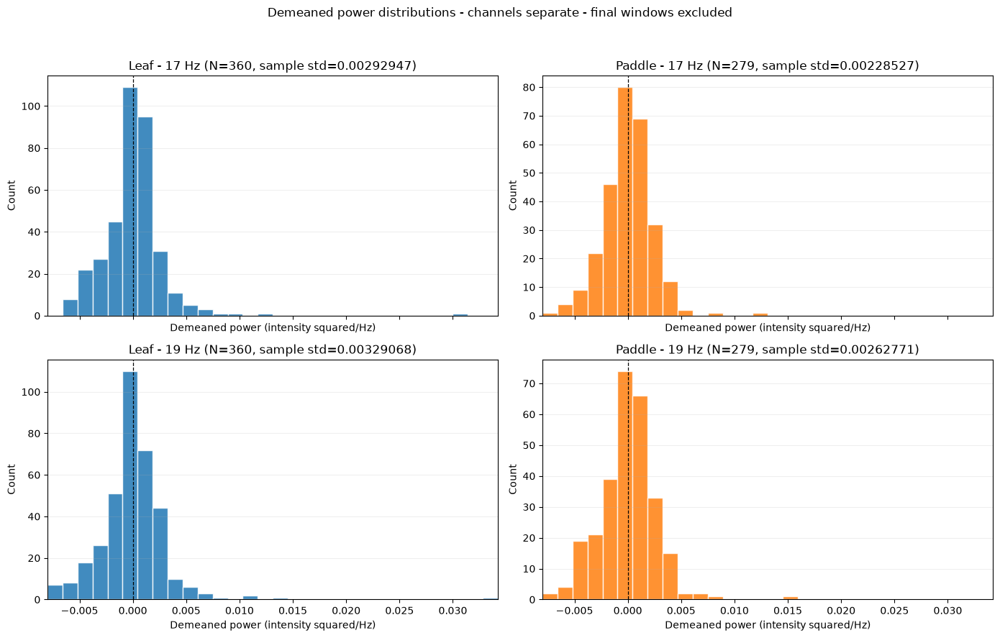

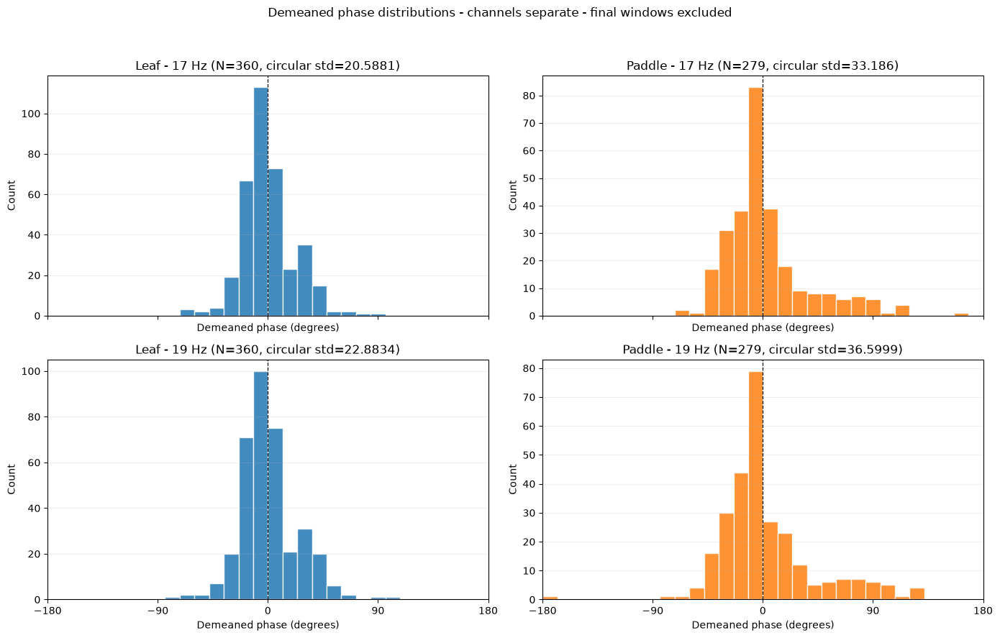

Standard deviations by game and stimulus channel (demeaned):
  game signal metric  points          std   method  ddof                units
  Leaf  17 Hz  Power     360 0.0029294678   sample     1 intensity squared/Hz
Paddle  17 Hz  Power     279 0.0022852655   sample     1 intensity squared/Hz
  Leaf  19 Hz  Power     360 0.0032906794   sample     1 intensity squared/Hz
Paddle  19 Hz  Power     279 0.0026277148   sample     1 intensity squared/Hz
  Leaf  17 Hz  Phase     360    20.588107 circular   NaN              degrees
Paddle  17 Hz  Phase     279    33.185993 circular   NaN              degrees
  Leaf  19 Hz  Phase     360    22.883367 circular   NaN              degrees
Paddle  19 Hz  Phase     279    36.599909 circular   NaN              degrees


In [69]:
# Power uses sample std (ddof=1); phase uses circular std in degrees.
HISTOGRAM_BINS = 30
STD_DDOF = 1


def circular_mean_degrees(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return np.nan
    resultant = np.mean(np.exp(1j * np.deg2rad(values)))
    # A zero resultant has no defined circular mean.
    if abs(resultant) <= 1e-12:
        return np.nan
    return float(np.rad2deg(np.angle(resultant)))


def circular_std_degrees(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return np.nan
    r = float(np.clip(abs(np.mean(np.exp(1j * np.deg2rad(values)))), 0, 1))
    return float(np.rad2deg(np.sqrt(-2 * np.log(r)))) if r > 0 else np.inf


def demean_trial_channels(series):
    """Arithmetic centering for power; circular centering for phase."""
    centered = series.copy()
    for field in ("power_psd", "phase_degrees"):
        values = pd.to_numeric(centered[field], errors="raise")
        centered[field] = values.where(np.isfinite(values), np.nan)
    groups = centered.groupby(["trial", "signal"])
    power_mean = groups["power_psd"].transform("mean")
    centered["power_psd_trial_mean"] = power_mean
    centered["power_psd_demeaned"] = centered["power_psd"] - power_mean
    phase_mean = groups["phase_degrees"].transform(circular_mean_degrees)
    centered["phase_degrees_trial_mean"] = phase_mean
    centered["phase_degrees_demeaned"] = (centered["phase_degrees"] - phase_mean + 180) % 360 - 180
    return centered


def plot_channel_histograms(leaf_series, paddle_series, demeaned=False, demoded=False):
    """Separate distributions by game, stimulus channel and metric."""
    std_rows = []
    if demeaned and demoded:
        raise ValueError("Choose one centering method.")
    mode = "Demoded" if demoded else ("Demeaned" if demeaned else "Original (no demeaning)")
    for field, metric, units in [
        ("power_psd", "Power", "intensity squared/Hz"),
        ("phase_degrees", "Phase", "degrees"),
    ]:
        value_column = field + "_demoded" if demoded else (field + "_demeaned" if demeaned else field)
        # Share bin edges across all four panels for this metric.
        # Combining values here sets the bin range only, not histogram counts.
        range_values = np.concatenate([
            leaf_series[value_column].dropna().to_numpy(),
            paddle_series[value_column].dropna().to_numpy(),
        ])
        bin_edges = (np.linspace(-180, 180, HISTOGRAM_BINS + 1)
                     if field == "phase_degrees" else
                     np.histogram_bin_edges(range_values, bins=HISTOGRAM_BINS))
        fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
        for row, signal in enumerate(("17 Hz", "19 Hz")):
            for col, (game, series, color) in enumerate([
                ("Leaf", leaf_series, "tab:blue"),
                ("Paddle", paddle_series, "tab:orange"),
            ]):
                ax = axes[row, col]
                # Pool trials for this channel only; never combine 17 and 19 Hz.
                values = series.loc[series["signal"] == signal, value_column].dropna().to_numpy()
                if field == "phase_degrees":
                    std = circular_std_degrees(values)
                    method, ddof = "circular", np.nan
                else:
                    std = float(np.std(values, ddof=STD_DDOF)) if len(values) > STD_DDOF else np.nan
                    method, ddof = "sample", STD_DDOF
                std_rows.append(dict(game=game, signal=signal, metric=metric,
                                     points=len(values), std=std, method=method,
                                     ddof=ddof, units=units))
                ax.hist(values, bins=bin_edges, color=color, edgecolor="white", alpha=0.85)
                if demeaned or demoded:
                    ax.axvline(0, color="black", linestyle="--", linewidth=0.9)
                ax.set_title(f"{game} - {signal} (N={len(values)}, {method} std={std:.6g})")
                ax.set_xlim(bin_edges[0], bin_edges[-1])
                ax.set_xlabel(f"{mode} {metric.lower()} ({units})")
                ax.set_ylabel("Count")
                if field == "phase_degrees":
                    ax.set_xticks([-180, -90, 0, 90, 180])
                ax.grid(axis="y", alpha=0.2)
        fig.suptitle(f"{mode} {metric.lower()} distributions - channels separate - final windows excluded")
        fig.tight_layout(rect=(0, 0, 1, 0.95))
        plt.show()
        plt.close(fig)
    return pd.DataFrame(std_rows)


leafDemeanedTimeSeries = demean_trial_channels(leafEpochTimeSeries)
paddleDemeanedTimeSeries = demean_trial_channels(paddleEpochTimeSeries)
demeanedHistogramStd = plot_channel_histograms(leafDemeanedTimeSeries,
                                               paddleDemeanedTimeSeries, demeaned=True)
print("Standard deviations by game and stimulus channel (demeaned):")
print(demeanedHistogramStd.to_string(index=False, float_format=lambda x: f"{x:.8g}"))


## Separate channel histograms without time-series demeaning
Eight additional histograms of the original retained epoch values: four power panels and four phase panels, with leaf/paddle columns and 17/19 Hz rows. Trials are pooled within each channel only. Shared bin edges within each metric; separate standard deviations by game/channel. Earlier FFT preprocessing is unchanged. Run the preceding histogram cell first for helpers and settings.


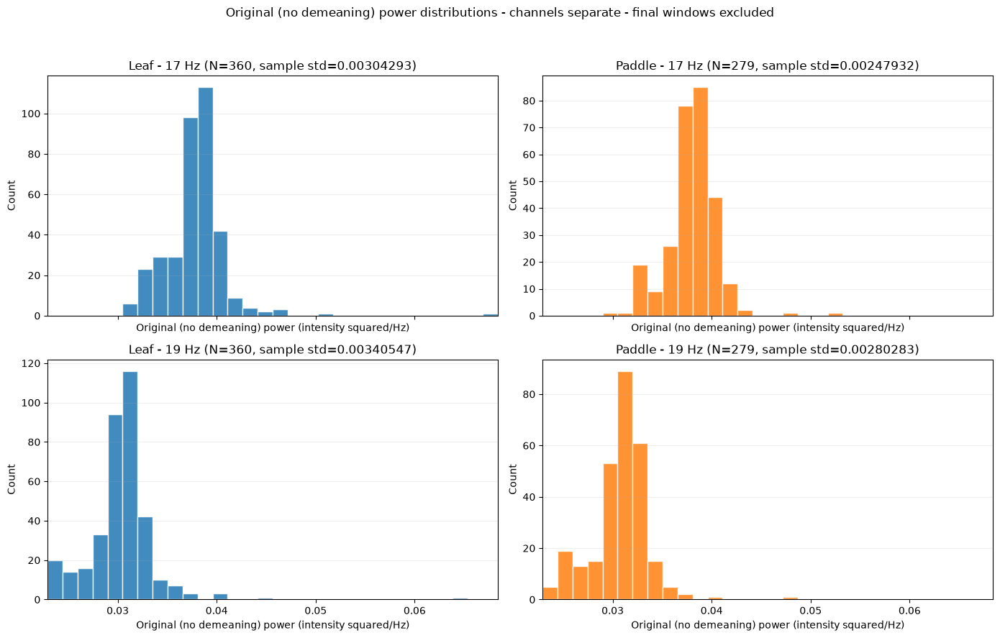

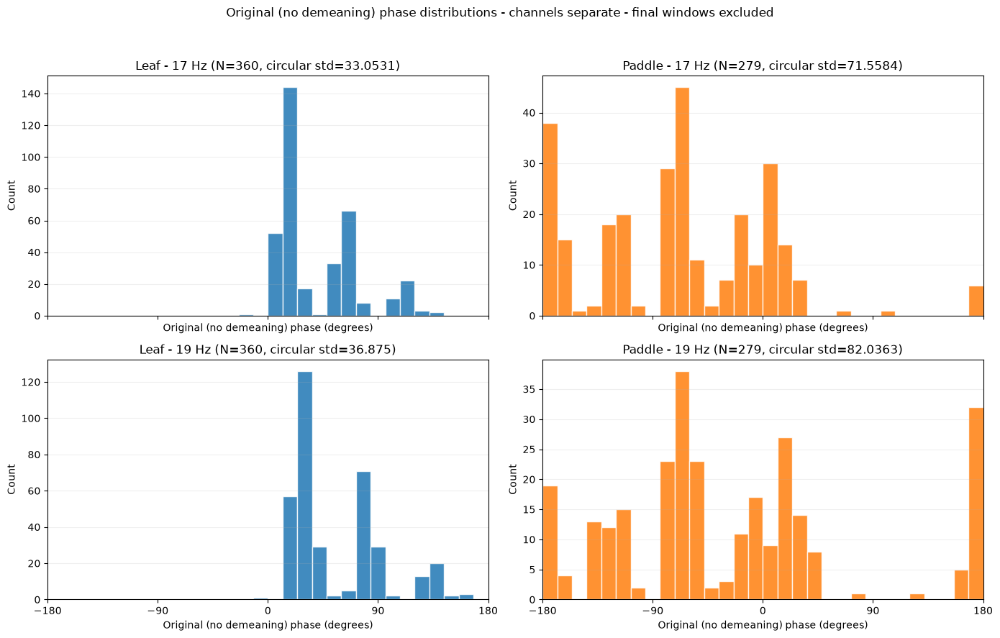

Standard deviations by game and stimulus channel (no demeaning):
  game signal metric  points          std   method  ddof                units
  Leaf  17 Hz  Power     360 0.0030429291   sample     1 intensity squared/Hz
Paddle  17 Hz  Power     279 0.0024793247   sample     1 intensity squared/Hz
  Leaf  19 Hz  Power     360 0.0034054685   sample     1 intensity squared/Hz
Paddle  19 Hz  Power     279 0.0028028278   sample     1 intensity squared/Hz
  Leaf  17 Hz  Phase     360    33.053102 circular   NaN              degrees
Paddle  17 Hz  Phase     279     71.55844 circular   NaN              degrees
  Leaf  19 Hz  Phase     360    36.874961 circular   NaN              degrees
Paddle  19 Hz  Phase     279    82.036309 circular   NaN              degrees


In [70]:
# Pool original retained epoch values across trials separately for each channel.
rawHistogramStd = plot_channel_histograms(leafEpochTimeSeries, paddleEpochTimeSeries,
                                          demeaned=False)
print("Standard deviations by game and stimulus channel (no demeaning):")
print(rawHistogramStd.to_string(index=False, float_format=lambda x: f"{x:.8g}"))


In [72]:
360/30

12.0

## Eight histograms after subtracting each trial/channel mode
Estimate the mode separately for each trial, channel, and metric as the center of its highest-count bin, then subtract it. `MODE_BINS` controls the mode estimate; shared estimation edges are used across games and channels. Tied modes choose the first maximum-count bin. Circular phase bins keep values near +/-180 together; phase residuals are wrapped into [-180,180).
Pool trials separately for each game/channel and show four power panels and four phase panels with shared plot edges. Print sample power std and circular phase std. Mode estimates depend on bin width and ties, especially for short trials. The demeaned and original histogram sets remain available. Run the preceding cells first.


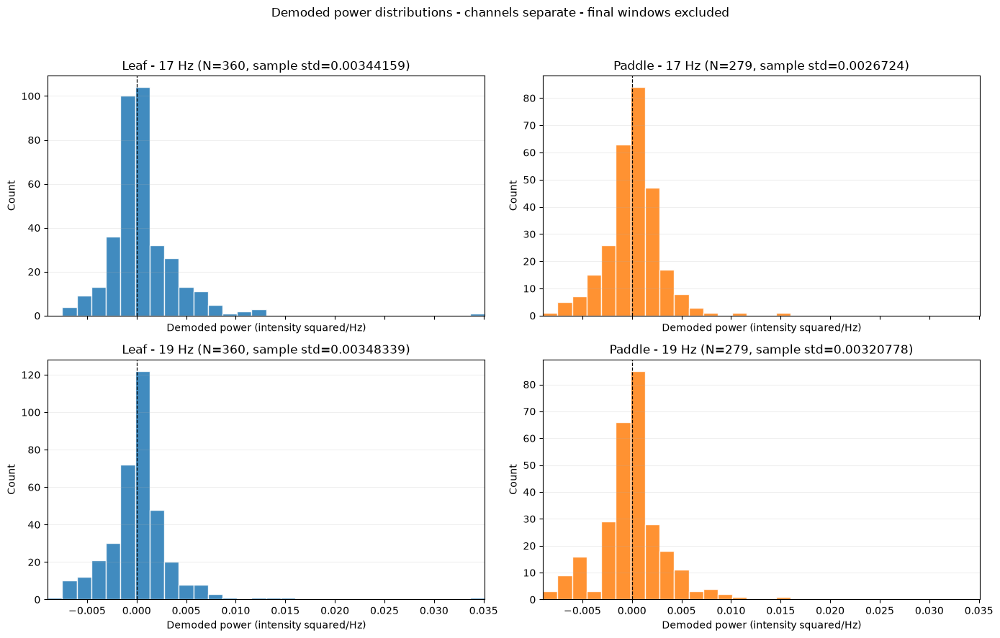

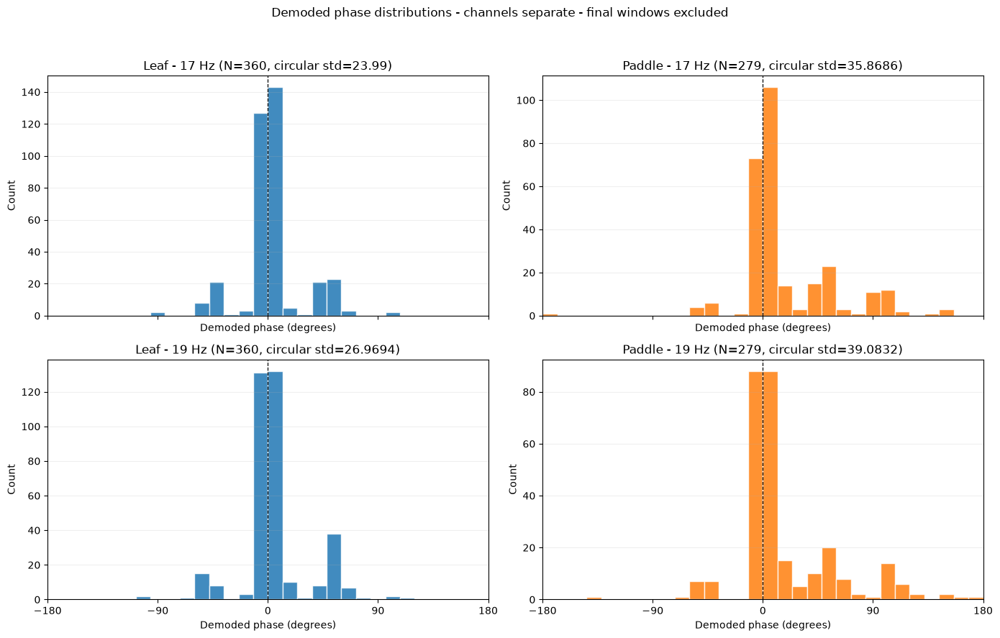

Standard deviations by game and stimulus channel (demoded):
  game signal metric  points          std   method  ddof                units
  Leaf  17 Hz  Power     360 0.0034415851   sample     1 intensity squared/Hz
Paddle  17 Hz  Power     279  0.002672398   sample     1 intensity squared/Hz
  Leaf  19 Hz  Power     360 0.0034833874   sample     1 intensity squared/Hz
Paddle  19 Hz  Power     279 0.0032077763   sample     1 intensity squared/Hz
  Leaf  17 Hz  Phase     360    23.990023 circular   NaN              degrees
Paddle  17 Hz  Phase     279    35.868646 circular   NaN              degrees
  Leaf  19 Hz  Phase     360    26.969351 circular   NaN              degrees
Paddle  19 Hz  Phase     279    39.083163 circular   NaN              degrees


In [71]:
# Mode estimation is histogram-based; change this independently of plot bins.
MODE_BINS = 30


def histogram_mode(values, edges, circular=False):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if not len(values):
        return np.nan
    if circular:
        # Wrap into the circular bin range before counting (including +/-180).
        values = (values - edges[0]) % 360 + edges[0]
    counts, _ = np.histogram(values, bins=edges)
    # Deterministic tie rule: first (lowest-position) maximum-count bin.
    index = int(np.argmax(counts))
    mode = float((edges[index] + edges[index + 1]) / 2)
    return (mode + 180) % 360 - 180 if circular else mode


def demode_trial_channels(series, mode_edges):
    centered = series.copy()
    for field in ("power_psd", "phase_degrees"):
        values = pd.to_numeric(centered[field], errors="raise")
        centered[field] = values.where(np.isfinite(values), np.nan)
        circular = field == "phase_degrees"
        modes = centered.groupby(["trial", "signal"])[field].transform(
            lambda x: histogram_mode(x, mode_edges[field], circular=circular))
        centered[field + "_trial_mode"] = modes
        residual = centered[field] - modes
        centered[field + "_demoded"] = (residual + 180) % 360 - 180 if circular else residual
    return centered


if isinstance(MODE_BINS, bool) or not isinstance(MODE_BINS, (int, np.integer)) or MODE_BINS < 2:
    raise ValueError("MODE_BINS must be an integer of at least 2.")
power_mode_values = np.concatenate([
    leafEpochTimeSeries["power_psd"].dropna().to_numpy(),
    paddleEpochTimeSeries["power_psd"].dropna().to_numpy(),
])
# Circular bins center one bin at -180, so values near +/-180 stay together.
phase_bin_width = 360 / MODE_BINS
trialModeBinEdges = {
    "power_psd": np.histogram_bin_edges(power_mode_values, bins=MODE_BINS),
    "phase_degrees": np.linspace(-180 - phase_bin_width / 2,
                                  180 - phase_bin_width / 2, MODE_BINS + 1),
}
leafDemodedTimeSeries = demode_trial_channels(leafEpochTimeSeries, trialModeBinEdges)
paddleDemodedTimeSeries = demode_trial_channels(paddleEpochTimeSeries, trialModeBinEdges)
demodedHistogramStd = plot_channel_histograms(leafDemodedTimeSeries,
                                              paddleDemodedTimeSeries, demoded=True)
print("Standard deviations by game and stimulus channel (demoded):")
print(demodedHistogramStd.to_string(index=False, float_format=lambda x: f"{x:.8g}"))
